# 01 · System Identification: measure how each corrector moves the beam

## Paired excitation

For corrector $j$ with initial setting $c_{j,0}$ the GUI measures the orbit at $c_{j,0}+h$ and $c_{j,0}-h$ (positive and negative kick).

With $\mathbf b(c)=\mathbf b_0+R_j\,c+\tfrac12 Q_j c^2+\dots$,
$$\mathbf b^+-\mathbf b^-=R_j\,(c^+-c^-)+\mathcal O(h^3),\qquad R_{ij}=\frac{\bar b_i^+-\bar b_i^-}{c_j^+-c_j^-}.$$
The static orbit $\mathbf b_0$, a slow linear drift and the quadratic term cancel. The applications use the readbacks $c^\pm$ (`bact`), not the requested values, because a clipped or unexecuted kick is not $2h$.

The GUI plots the **half difference** (orbit excursion)
$$Diff_i=\frac{\bar b_i^+-\bar b_i^-}{2}=R_{ij}\,h .$$

## Uncertainty

With shot-to-shot noise $\sigma$ and $N$ BPM samples per acquisition, $u(\bar b^\pm)=\sigma/\sqrt N$ and
$$u(D)=\frac{\sigma}{\sqrt{2N}},\qquad u(R_{ij})=\frac{\sigma}{h\sqrt{2N}},\qquad \frac{u(R_{ij})}{|R_{ij}|}=\frac{\sigma}{|D_i|\sqrt{2N}} .$$
The relative precision is set by the **orbit excursion** $|D|$, not by the kick itself. This is why the GUI asks for a *target orbit excursion* and finds the kick that produces it.

**Run:** follow [the setup guide](README.md), select the **Flight tutorials** kernel, then **Restart Kernel and Run All Cells**.

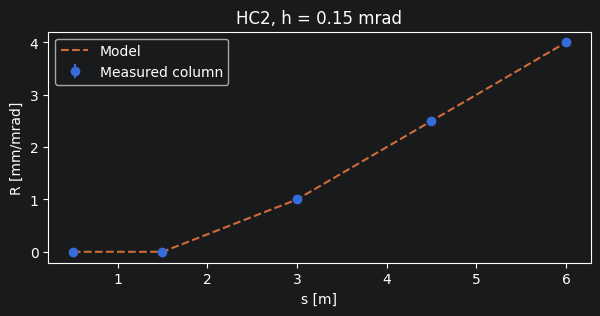

Restored: True


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from tutorial_support import Beamline

machine = Beamline(seed=7, noise_mm=0.005)
initial = machine.settings.copy()
name, j, h = 'HC2', 1, 0.15

def paired(name, h):
    j = machine.correctors.index(name)
    try:
        machine.set_correctors([name], [initial[j] + h])
        plus = machine.get_state()
        machine.set_correctors([name], [initial[j] - h])
        minus = machine.get_state()
    finally:
        machine.set_correctors(machine.correctors, initial)
    return plus, minus

plus, minus = paired(name, h)
op, om = plus.get_orbit(), minus.get_orbit()
denominator = plus.get_correctors([name])['bact'][0] - minus.get_correctors([name])['bact'][0]
column = (op['x'] - om['x']) / denominator
uncertainty = np.sqrt(op['stdx']**2 / op['nshots'] + om['stdx']**2 / om['nshots']) / abs(denominator)

fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(machine.s_bpms, column, yerr=uncertainty, fmt='o', label='Measured column')
ax.plot(machine.s_bpms, machine.R[:5, j], '--', label='Model')
ax.set(xlabel='s [m]', ylabel='R [mm/mrad]', title=f'{name}, h = {h} mrad')
ax.legend()
plt.show()
print('Restored:', np.array_equal(machine.settings, initial))

## What the GUI does in one scan

For each cycle (**Number of cycles**) and each selected corrector:

1. sets $c_0+h$, clipped to $\pm c_{max}$ (**Max strength**), and saves the snapshot `DATA_<corrector>_p<cycle>.pkl`;
2. sets $c_0-h$ and saves `DATA_<corrector>_m<cycle>.pkl`;
3. restores $c_0$; if the readback does not return, the scan stops;
4. plots $Diff$ in both planes with error bars;
5. adapts the kick for the next cycle and writes it to `kicks.txt`.

Existing files are not measured again, so an interrupted scan can be resumed in the same directory. The Response Matrix code later uses **all** cycles together.

## Kick adaptation

With the largest observed excursion $D_{obs}=\max_i|D_i|$ in the corrector's own plane and the target excursion $A$, SysID computes
$$s=\mathrm{clip}\!\left(\frac{A}{D_{obs}},\,0.8,\,2\right),\qquad h'=\min(s\,h,\;c_{max}),\qquad h_{next}=0.8\,h'+0.2\,h .$$
If nothing was observed, $s=1.5$. A kick therefore grows by at most a factor $1.8$ and shrinks by at most $0.84$ per cycle.

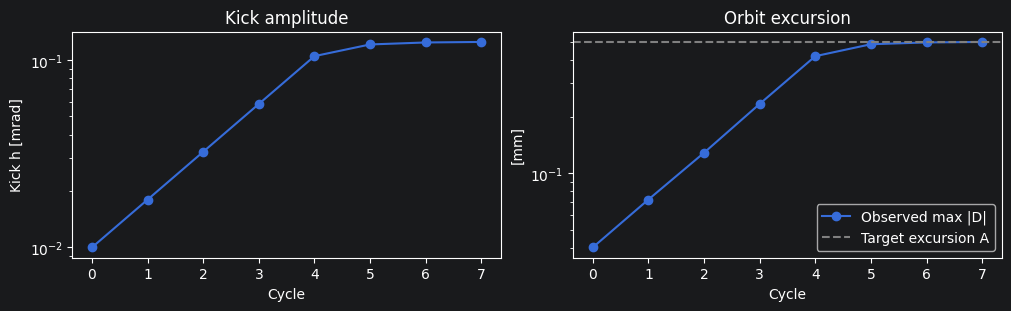

In [2]:
def update_amplitude(kick, observed, target, max_strength):
    scale = np.clip(target / observed, 0.8, 2.0) if observed > 0 else 1.5
    return 0.8 * min(kick * scale, max_strength) + 0.2 * kick

target, max_strength, kick, history = 0.5, 1.0, 0.01, []
for cycle in range(8):
    plus, minus = paired(name, kick)
    observed = np.max(np.abs(plus.get_orbit()['x'] - minus.get_orbit()['x'])) / 2
    history.append((kick, observed))
    kick = update_amplitude(kick, observed, target, max_strength)
history = np.array(history)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
axes[0].semilogy(history[:, 0], 'o-')
axes[0].set(xlabel='Cycle', ylabel='Kick h [mrad]', title='Kick amplitude')
axes[1].semilogy(history[:, 1], 'o-', label='Observed max |D|')
axes[1].axhline(target, color='gray', ls='--', label='Target excursion A')
axes[1].set(xlabel='Cycle', ylabel='[mm]', title='Orbit excursion')
axes[1].legend()
plt.show()

## Precision versus target excursion

Here, we see that bigger target orbit excursion helps with measuring the Respone Matrix, because the kick is more visible compared to the noise of the BPMs, for example.

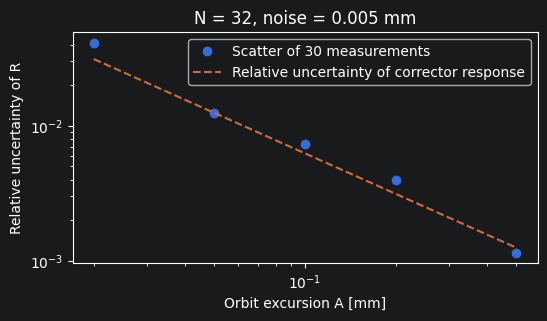

In [7]:
excursions = np.array([0.02, 0.05, 0.1, 0.2, 0.5])
spread = []
for A in excursions:
    kick = A / np.max(np.abs(machine.R[:5, j]))
    values = []
    for _ in range(30):
        plus, minus = paired(name, kick)
        values.append((plus.get_orbit()['x'][-1] - minus.get_orbit()['x'][-1]) / (2 * kick))
    spread.append(np.std(values) / abs(machine.R[4, j]))

fig, ax = plt.subplots(figsize=(6, 3))
ax.loglog(excursions, spread, 'o', label='Scatter of 30 measurements')
ax.loglog(excursions, machine.noise_mm / (excursions * np.sqrt(2 * machine.nsamples)), '--', label='Relative uncertainty of corrector response')
ax.set(xlabel='Orbit excursion A [mm]', ylabel='Relative uncertainty of R', title=f'N = {machine.nsamples}, noise = {machine.noise_mm} mm')
ax.legend()
plt.show()

## Choosing the parameters

| GUI field | Symbol | Default | How to choose |
|---|---|---|---|
| Correction Mode | – | Orbit Correction | *Orbit* for orbit steering and bumps. *Changed energy* and *Changed intensity* repeat the scan with the beam changed, for DFS and WFS. *All modes at once* runs the three, each in its own directory. |
| Target orbit excursion H/V | $A$ | 0.5 (machine units, CLEAR 5 mm) | Large enough for the precision you need, small enough to stay linear and avoid losses. |
| Initial hkick / vkick | $h_0$ | interface value (`sysid_corrector_kick`) | Initial kick in starting iteration of SysID.|
| Max strength H/V | $c_{max}$ | $1.15\max|c|$ of the plane | Absolute limit $|c_0\pm h|\le c_{max}$; it also caps the kick. Too tight a limit clips kicks and reduces $D$. |
| Number of cycles | – | 2 | The first cycle finds the kick, later cycles measure at the target. |
| BPM samples | $N$ | interface `nsamples` | See [Machine interface](00_MachineInterface.ipynb). |

The error bars in the GUI plot are $\sqrt{s_+^2+s_-^2}/\sqrt N$, i.e. the uncertainty of the full difference $b^+-b^-$.